# SentraGrade: leakage-corrected split vs the old day-grouped split (ResNet50, PyTorch)

This notebook trains the **same ResNet50 with the same code** under two split protocols, for all six leave-one-class-out folds, so the only difference between the two sets of numbers is the split.

| Protocol | Train / val / test | Known negatives for AUROC & FPR@95 | Threshold |
|---|---|---|---|
| `old` (paper) | the original `folds/fold*_train.csv` and `fold*_val.csv` (random 20% of capture days per class), no test set | val (also used for early stopping) | 95th pct of val |
| `corrected` | **time-blocked per class**: earliest ~60% of capture days = train, then **1 buffer day dropped**, then the next days = val, the last days = test | **test** (never seen during training or selection) | 95th pct of val, then checked on test |

Why: the small classes are one fruit photographed over about a week, so the old split put the same fruit on neighbouring days in train and val. Time blocks plus a dropped buffer day keep the closest days apart, and a separate test set stops threshold and model selection from using the reported data.

**Caveat to state in the paper:** with roughly one specimen per class, no split is fully specimen-free, and the corrected test days are the latest (most ripe/spoiled) days, so part of any drop is ageing shift, not only leakage. Set `SPLIT_DIRECTION = "reverse"` to train on the latest days and test on the earliest as a robustness check.

**Kaggle setup:** add the `sentragrade_data.zip` as a dataset (Add Input → Upload; Kaggle unzips it), turn on **GPU (T4 or P100)** and **Internet** (for the ImageNet weights), then Run All. Roughly 1 to 1.5 h on a T4. Outputs go to `/kaggle/working/sentragrade_leakage/` and are zipped at the end.

In [1]:
import os, json, time, math, random, shutil, glob
from pathlib import Path
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet50, ResNet50_Weights
from PIL import Image
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt

# ---------------- config ----------------
SEED = 42
CLASSES = ["Banana", "Carrot", "Guava", "Indian_Gooseberry", "Mango", "Tomato"]
PROTOCOLS = ["old", "corrected"]   # run both so the comparison uses identical code
FOLDS = list(range(6))
SPLIT_DIRECTION = "forward"        # "forward": train on earliest days; "reverse": train on latest days
TRAIN_FRAC = 0.60                  # share of a class's images (whole days) used for training
BUFFER_DAYS = 1                    # days dropped between train and val
EPOCHS, PATIENCE, BATCH = 25, 6, 32
LR_BACKBONE, LR_HEAD, WD = 1e-4, 1e-3, 1e-4
N_BOOT = 1000                      # session-level bootstrap resamples for AUROC CIs
SESSION_GAP_MIN = 5                # photos more than 5 min apart start a new capture session
QUICK = False                      # True = 1 epoch, 2 folds, small subsets (smoke test only)

def find_data_root():
    env = os.environ.get("SENTRAGRADE_DATA_ROOT")
    if env:
        return Path(env)
    hits = glob.glob("/kaggle/input/**/manifest_full.csv", recursive=True)
    if hits:
        return Path(hits[0]).parent
    return Path("~/sentragrade_data").expanduser()

DATA_ROOT = find_data_root()
OUT = Path("/kaggle/working/sentragrade_leakage") if Path("/kaggle/working").exists() else Path("outputs/sentragrade_leakage")
OUT.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))
NUM_WORKERS = 2 if DEVICE.type == "cuda" else 0

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)
if QUICK:
    EPOCHS, FOLDS, N_BOOT = 1, [0, 3], 50
print("data root:", DATA_ROOT, "| device:", DEVICE, "| output:", OUT)
assert (DATA_ROOT / "manifest_full.csv").exists(), "manifest_full.csv not found: attach sentragrade_data.zip as a dataset"

data root: /kaggle/input/datasets/riteesh23f3002667/sentragrade-data | device: cuda | output: /kaggle/working/sentragrade_leakage


## 1. Build both split protocols and check them

In [2]:
man = pd.read_csv(DATA_ROOT / "manifest_full.csv", dtype={"date": str, "time": str})
man["path"] = [str(DATA_ROOT / "resized" / c / f) for c, f in zip(man.class_name, man.filename)]
missing = [p for p in man.path if not os.path.exists(p)]
assert not missing, f"{len(missing)} images missing, e.g. {missing[:3]}"

# capture sessions: a burst of ~17 photos; used as the resampling unit for the bootstrap
man["ts"] = pd.to_datetime(man.date + man.time.str.zfill(6), format="%Y%m%d%H%M%S")
man = man.sort_values(["class_name", "ts"]).reset_index(drop=True)
gap = man.groupby("class_name").ts.diff() > pd.Timedelta(minutes=SESSION_GAP_MIN)
man["session"] = man.class_name + "_" + gap.groupby(man.class_name).cumsum().astype(str)
key = dict(zip(man.class_name + "/" + man.filename, man.session))

def blocked_split(d):
    # whole capture days, in time order; train block, buffer day(s) dropped, then val and test blocks
    days = sorted(d.date.unique(), reverse=(SPLIT_DIRECTION == "reverse"))
    n = d.groupby("date").size().reindex(days).values
    cum = np.cumsum(n) / n.sum()
    n_tr = max(1, int((cum <= TRAIN_FRAC).sum()))
    tr = days[:n_tr]
    rest = days[n_tr + BUFFER_DAYS:]
    assert len(rest) >= 2, f"{d.class_name.iloc[0]}: not enough days left for val and test"
    k = max(1, len(rest) // 2)
    return tr, days[n_tr:n_tr + BUFFER_DAYS], rest[:k], rest[k:]

split_days, rows = {}, []
for c, d in man.groupby("class_name"):
    tr, buf, va, te = blocked_split(d)
    split_days[c] = dict(train=tr, buffer=buf, val=va, test=te)
    rows.append({"class": c, "days": d.date.nunique(),
                 "train_days": f"{tr[0]}..{tr[-1]} ({len(tr)})", "buffer": ",".join(buf),
                 "val_days": ",".join(va), "test_days": ",".join(te),
                 "train_n": d.date.isin(tr).sum(), "val_n": d.date.isin(va).sum(),
                 "test_n": d.date.isin(te).sum(), "dropped_n": d.date.isin(buf).sum()})
corrected_table = pd.DataFrame(rows)
display(corrected_table)
corrected_table.to_csv(OUT / "corrected_split_days.csv", index=False)

def tag(df):
    df = df.copy()
    df["path"] = [str(DATA_ROOT / "resized" / c / f) for c, f in zip(df.class_name, df.filename)]
    df["session"] = (df.class_name + "/" + df.filename).map(key)
    return df

def get_fold(protocol, k):
    held = CLASSES[k]
    known = [c for c in CLASSES if c != held]
    label_map = {c: i for i, c in enumerate(sorted(known))}
    ood = man[man.class_name == held]
    if protocol == "old":
        tr = tag(pd.read_csv(DATA_ROOT / "folds" / f"fold{k}_train.csv", dtype={"date": str}))
        va = tag(pd.read_csv(DATA_ROOT / "folds" / f"fold{k}_val.csv", dtype={"date": str}))
        te = va                    # the paper reports on val: reproduce that exactly
    else:
        kn = man[man.class_name != held]
        pick = lambda part: pd.concat([kn[(kn.class_name == c) & kn.date.isin(split_days[c][part])] for c in known])
        tr, va, te = pick("train"), pick("val"), pick("test")
        # checks: no capture day shared between blocks, buffer gap respected, test unseen
        for c in known:
            s = split_days[c]
            assert not (set(s["train"]) & set(s["val"])) and not (set(s["train"]) & set(s["test"])) and not (set(s["val"]) & set(s["test"]))
        assert set(tr.path).isdisjoint(te.path) and set(va.path).isdisjoint(te.path) and set(tr.path).isdisjoint(va.path)
    assert held not in set(tr.class_name) | set(va.class_name) | set(te.class_name)
    if QUICK:
        tr = tr.groupby("class_name").head(40); va = va.groupby("class_name").head(20)
        te = te.groupby("class_name").head(20) if protocol == "corrected" else va; ood = ood.head(60)
    return dict(train=tr, val=va, test=te, ood=ood, label_map=label_map, held=held)

summary = []
for p in PROTOCOLS:
    for k in FOLDS:
        f = get_fold(p, k)
        summary.append({"protocol": p, "fold": k, "held_out": f["held"], "train": len(f["train"]),
                        "val": len(f["val"]), "test": len(f["test"]) if p == "corrected" else "= val", "ood": len(f["ood"])})
display(pd.DataFrame(summary))

,class,days,train_days,buffer,val_days,test_days,train_n,val_n,test_n,dropped_n
0,Banana,7,20250911..20250915 (4),20250916,20250917,20250918,187,51,51,34
1,Carrot,9,20250725..20250730 (5),20250731,20250801,"20250802,20250804",255,50,102,51
2,Guava,10,20250625..20250701 (6),20250702,20250703,"20250704,20250705",306,51,102,51
3,Indian_Gooseberry,30,20250723..20250811 (17),20250812,"20250813,20250814,20250815,20250816,20250818,2...","20250830,20250901,20250902,20250903,20250904,2...",833,272,255,51
4,Mango,8,20250920..20250924 (4),20250926,20250929,"20250930,20251003",205,34,102,51
5,Tomato,48,20250723..20250902 (27),20250903,"20250904,20250908,20250909,20250910,20250911,2...","20250918,20250919,20250920,20250922,20250923,2...",1309,442,442,51


,protocol,fold,held_out,train,val,test,ood
0,old,0,Banana,3978,1037,= val,323
1,old,1,Carrot,3843,1037,= val,458
2,old,2,Guava,3791,1037,= val,510
3,old,3,Indian_Gooseberry,3077,850,= val,1411
4,old,4,Mango,3892,1054,= val,392
5,old,5,Tomato,2414,680,= val,2244
6,corrected,0,Banana,2908,849,1003,323
7,corrected,1,Carrot,2840,850,952,458
8,corrected,2,Guava,2789,849,952,510
9,corrected,3,Indian_Gooseberry,2262,628,799,1411


## 2. Data, model and training (same settings as the paper's ResNet50)

In [3]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.75, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.1),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([
    transforms.Resize(256), transforms.CenterCrop(224),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class ImgDS(Dataset):
    def __init__(self, df, label_map, tf):
        self.paths = df.path.tolist()
        self.labels = [label_map.get(c, -1) for c in df.class_name]
        self.tf = tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        with Image.open(self.paths[i]) as im:
            return self.tf(im.convert("RGB")), self.labels[i]

def loader(df, lm, tf, shuffle):
    return DataLoader(ImgDS(df, lm, tf), batch_size=BATCH, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda")

class ResNetClassifier(nn.Module):
    # identical layout and weights (IMAGENET1K_V2) to the paper's run and app/server.py
    def __init__(self, num_classes, pretrained=True):
        super().__init__()
        b = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
        self.stem = nn.Sequential(b.conv1, b.bn1, b.relu, b.maxpool)
        self.layer1, self.layer2, self.layer3, self.layer4 = b.layer1, b.layer2, b.layer3, b.layer4
        self.avgpool = b.avgpool
        self.fc = nn.Linear(b.fc.in_features, num_classes)
    def forward(self, x):
        x = self.layer4(self.layer3(self.layer2(self.layer1(self.stem(x)))))
        feats = torch.flatten(self.avgpool(x), 1)
        return self.fc(feats), feats

def build_model(n):
    m = ResNetClassifier(n)
    for mod in [m.stem, m.layer1, m.layer2]:   # conv1..layer2 frozen, as in the paper
        for p in mod.parameters():
            p.requires_grad = False
    return m.to(DEVICE)

@torch.no_grad()
def run_eval(model, dl):
    model.eval()
    L, Fe, Y = [], [], []
    for x, y in dl:
        with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
            lo, fe = model(x.to(DEVICE, non_blocking=True))
        L.append(lo.float().cpu()); Fe.append(fe.float().cpu()); Y.append(y)
    return torch.cat(L), torch.cat(Fe), torch.cat(Y)

def train_fold(f):
    set_seed(SEED)
    lm = f["label_map"]; n = len(lm)
    model = build_model(n)
    counts = f["train"].class_name.map(lm).value_counts().reindex(range(n)).values
    w = torch.tensor(counts.sum() / (n * counts), dtype=torch.float32, device=DEVICE)  # inverse class frequency
    crit = nn.CrossEntropyLoss(weight=w)
    head = list(model.fc.parameters())
    back = [p for name, p in model.named_parameters() if p.requires_grad and not name.startswith("fc.")]
    opt = torch.optim.AdamW([{"params": back, "lr": LR_BACKBONE}, {"params": head, "lr": LR_HEAD}], weight_decay=WD)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    scaler = torch.cuda.amp.GradScaler(enabled=DEVICE.type == "cuda")
    dl_tr = loader(f["train"], lm, train_tf, True)
    dl_va = loader(f["val"], lm, eval_tf, False)
    best, best_acc, bad, hist = None, -1.0, 0, []
    for ep in range(1, EPOCHS + 1):
        model.train(); t0 = time.time(); tl, tn = 0.0, 0
        for x, y in dl_tr:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
                loss = crit(model(x)[0], y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(y); tn += len(y)
        sched.step()
        lo, _, yv = run_eval(model, dl_va)
        vacc = (lo.argmax(1) == yv).float().mean().item()
        vloss = F.cross_entropy(lo, yv, weight=w.cpu()).item()
        hist.append({"epoch": ep, "train_loss": tl / tn, "val_loss": vloss, "val_acc": vacc})
        print(f"    ep {ep:2d}  train_loss {tl/tn:.4f}  val_loss {vloss:.4f}  val_acc {vacc:.4f}  ({time.time()-t0:.0f}s)")
        if vacc > best_acc:                     # early stopping on val accuracy, same rule as the paper's run
            best_acc, bad = vacc, 0
            best = {kk: v.detach().cpu().clone() for kk, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                break
    model.load_state_dict(best)
    return model, pd.DataFrame(hist)

## 3. Scores and metrics

In [4]:
def scores_from(logits, feats, protos):
    p = logits.softmax(1)
    return {"msp": (-p.max(1).values).numpy(),
            "energy": (-torch.logsumexp(logits, 1)).numpy(),
            "proto": torch.cdist(feats, protos).min(1).values.numpy()}

def fpr_at_95(neg, pos):
    thr = np.percentile(pos, 5)            # catch 95% of held-out images
    return float((neg >= thr).mean())

def boot_auroc(neg, pos, neg_sess, pos_sess, rng):
    # resample whole capture sessions, not single photos (photos in a burst are near-copies)
    ns, ps = pd.Series(neg).groupby(neg_sess).apply(np.array), pd.Series(pos).groupby(pos_sess).apply(np.array)
    out = []
    for _ in range(N_BOOT):
        a = np.concatenate(ns.values[rng.integers(0, len(ns), len(ns))])
        b = np.concatenate(ps.values[rng.integers(0, len(ps), len(ps))])
        out.append(roc_auc_score(np.r_[np.zeros(len(a)), np.ones(len(b))], np.r_[a, b]))
    return np.percentile(out, [2.5, 97.5])

def evaluate(model, f, protocol, k):
    lm = f["label_map"]
    tr = run_eval(model, loader(f["train"], lm, eval_tf, False))
    va = run_eval(model, loader(f["val"], lm, eval_tf, False))
    te = va if protocol == "old" else run_eval(model, loader(f["test"], lm, eval_tf, False))
    od = run_eval(model, loader(f["ood"], lm, eval_tf, False))
    protos = torch.stack([tr[1][tr[2] == c].mean(0) for c in range(len(lm))])   # class means of training embeddings
    S = {name: scores_from(lo, fe, protos) for name, (lo, fe, _) in {"val": va, "test": te, "ood": od}.items()}
    rng = np.random.default_rng(SEED)
    te_sess = (f["val"] if protocol == "old" else f["test"]).session.values
    ood_sess = f["ood"].session.values
    rows = []
    for m in ["msp", "energy", "proto"]:
        neg, pos = S["test"][m], S["ood"][m]
        y = np.r_[np.zeros(len(neg)), np.ones(len(pos))]
        thr = np.percentile(S["val"][m], 95)                    # operating threshold set on val only
        lo_ci, hi_ci = boot_auroc(neg, pos, te_sess, ood_sess, rng)
        rows.append({"protocol": protocol, "fold": k, "held_out": f["held"], "method": m,
                     "AUROC": roc_auc_score(y, np.r_[neg, pos]), "AUROC_lo": lo_ci, "AUROC_hi": hi_ci,
                     "FPR95": fpr_at_95(neg, pos),
                     "test_false_reject_at_val_thr": float((neg > thr).mean()),
                     "ood_caught_at_val_thr": float((pos > thr).mean()),
                     "n_neg": len(neg), "n_pos": len(pos),
                     "n_neg_sessions": len(set(te_sess)), "n_pos_sessions": len(set(ood_sess))})
    acc = {"protocol": protocol, "fold": k, "held_out": f["held"],
           "val_acc": (va[0].argmax(1) == va[2]).float().mean().item(),
           "test_acc": (te[0].argmax(1) == te[2]).float().mean().item()}
    # forced labels: what the closed-set model would call each held-out image
    inv = {v: kk for kk, v in lm.items()}
    pred = od[0].argmax(1).numpy()
    forced = pd.Series([inv[i] for i in pred]).value_counts(normalize=True)
    acc["forced_label"] = f"{forced.index[0]} ({forced.iloc[0]:.1%})"
    acc["ood_mean_msp"] = od[0].softmax(1).max(1).values.mean().item()
    bundle = {"label_map": lm, "train": dict(zip(["logits", "features", "labels"], tr)),
              "val": dict(zip(["logits", "features", "labels"], va)),
              "test": dict(zip(["logits", "features", "labels"], te)),
              "ood": dict(zip(["logits", "features", "labels"], od))}
    return rows, acc, bundle

## 4. Train and evaluate every protocol and fold

Results are written after each fold, so if the session stops you can re-run this cell and finished folds are skipped.

In [5]:
res_path, acc_path = OUT / "ood_eval_per_fold.csv", OUT / "known_accuracy.csv"
res = pd.read_csv(res_path) if res_path.exists() else pd.DataFrame()
accs = pd.read_csv(acc_path) if acc_path.exists() else pd.DataFrame()
done = set(zip(res.protocol, res.fold)) if len(res) else set()

for p in PROTOCOLS:
    for k in FOLDS:
        if (p, k) in done:
            print(f"skip {p} fold {k} (done)"); continue
        f = get_fold(p, k)
        print(f"\n=== {p} | fold {k} | held out {f['held']} | train {len(f['train'])} val {len(f['val'])} ===")
        t0 = time.time()
        model, hist = train_fold(f)
        rows, acc, bundle = evaluate(model, f, p, k)
        hist.to_csv(OUT / f"history_{p}_fold{k}.csv", index=False)
        ck = {"model_state_dict": model.state_dict(), **bundle,
              "protocol": p, "split_direction": SPLIT_DIRECTION, "held_out": f["held"]}
        if p == "corrected":
            torch.save(ck, OUT / f"resnet50_{p}_fold{k}.pt")       # weights kept for Energy-CAM / novelty maps later
        else:
            ck.pop("model_state_dict"); torch.save(ck, OUT / f"scores_{p}_fold{k}.pt")
        res = pd.concat([res, pd.DataFrame(rows)], ignore_index=True); res.to_csv(res_path, index=False)
        accs = pd.concat([accs, pd.DataFrame([acc])], ignore_index=True); accs.to_csv(acc_path, index=False)
        print(pd.DataFrame(rows)[["method", "AUROC", "AUROC_lo", "AUROC_hi", "FPR95"]].round(4).to_string(index=False))
        print(f"  known acc: val {acc['val_acc']:.4f}  test {acc['test_acc']:.4f} | forced label {acc['forced_label']} | {time.time()-t0:.0f}s")
        del model; torch.cuda.empty_cache() if DEVICE.type == "cuda" else None


=== old | fold 0 | held out Banana | train 3978 val 1037 ===
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 203MB/s]
/tmp/ipykernel_23/2311386707.py:67: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=DEVICE.type == "cuda")


    ep  1  train_loss 0.1171  val_loss 0.0001  val_acc 1.0000  (211s)
    ep  2  train_loss 0.0028  val_loss 0.0001  val_acc 1.0000  (16s)
    ep  3  train_loss 0.0074  val_loss 0.0004  val_acc 1.0000  (16s)
    ep  4  train_loss 0.0010  val_loss 0.0001  val_acc 1.0000  (16s)
    ep  5  train_loss 0.0003  val_loss 0.0000  val_acc 1.0000  (16s)
    ep  6  train_loss 0.0001  val_loss 0.0000  val_acc 1.0000  (16s)
    ep  7  train_loss 0.0002  val_loss 0.0000  val_acc 1.0000  (16s)
method  AUROC  AUROC_lo  AUROC_hi  FPR95
   msp 0.9994    0.9984       1.0 0.0000
energy 0.9999    0.9996       1.0 0.0000
 proto 0.9988    0.9963       1.0 0.0048
  known acc: val 1.0000  test 1.0000 | forced label Guava (42.1%) | 333s

=== old | fold 1 | held out Carrot | train 3843 val 1037 ===


/tmp/ipykernel_23/2311386707.py:67: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=DEVICE.type == "cuda")


    ep  1  train_loss 0.1529  val_loss 0.0022  val_acc 1.0000  (16s)
    ep  2  train_loss 0.0116  val_loss 0.0004  val_acc 1.0000  (15s)
    ep  3  train_loss 0.0019  val_loss 0.0001  val_acc 1.0000  (15s)
    ep  4  train_loss 0.0006  val_loss 0.0001  val_acc 1.0000  (15s)
    ep  5  train_loss 0.0012  val_loss 0.0001  val_acc 1.0000  (16s)
    ep  6  train_loss 0.0005  val_loss 0.0000  val_acc 1.0000  (15s)
    ep  7  train_loss 0.0002  val_loss 0.0000  val_acc 1.0000  (15s)
method  AUROC  AUROC_lo  AUROC_hi  FPR95
   msp 0.9950    0.9902    0.9987 0.0183
energy 0.9984    0.9966    0.9996 0.0087
 proto 0.9907    0.9827    0.9964 0.0338
  known acc: val 1.0000  test 1.0000 | forced label Banana (76.2%) | 123s

=== old | fold 2 | held out Guava | train 3791 val 1037 ===


/tmp/ipykernel_23/2311386707.py:67: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=DEVICE.type == "cuda")


... (15 outputs left out)

/tmp/ipykernel_23/2311386707.py:67: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=DEVICE.type == "cuda")


    ep  1  train_loss 0.1456  val_loss 0.0433  val_acc 1.0000  (12s)
    ep  2  train_loss 0.0006  val_loss 0.0207  val_acc 0.9988  (12s)
    ep  3  train_loss 0.0074  val_loss 0.0670  val_acc 0.9919  (12s)
    ep  4  train_loss 0.0004  val_loss 0.0309  val_acc 0.9954  (12s)
    ep  5  train_loss 0.0006  val_loss 0.2454  val_acc 0.9492  (12s)
    ep  6  train_loss 0.0003  val_loss 0.1823  val_acc 0.9711  (12s)
    ep  7  train_loss 0.0002  val_loss 0.1410  val_acc 0.9804  (12s)
method  AUROC  AUROC_lo  AUROC_hi  FPR95
   msp 0.8763    0.8132    0.9270 0.2637
energy 0.9145    0.8605    0.9571 0.2290
 proto 0.9086    0.8497    0.9596 0.1943
  known acc: val 1.0000  test 0.9443 | forced label Guava (91.6%) | 99s

=== corrected | fold 5 | held out Tomato | train 1786 val 458 ===


/tmp/ipykernel_23/2311386707.py:67: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=DEVICE.type == "cuda")


    ep  1  train_loss 0.2215  val_loss 0.0344  val_acc 0.9913  (8s)
    ep  2  train_loss 0.0029  val_loss 0.0614  val_acc 0.9913  (8s)
    ep  3  train_loss 0.0042  val_loss 0.0396  val_acc 0.9934  (7s)
    ep  4  train_loss 0.0056  val_loss 0.0330  val_acc 0.9956  (7s)
    ep  5  train_loss 0.0049  val_loss 0.0432  val_acc 0.9913  (7s)
    ep  6  train_loss 0.0013  val_loss 0.0116  val_acc 1.0000  (7s)
    ep  7  train_loss 0.0002  val_loss 0.0113  val_acc 1.0000  (7s)
    ep  8  train_loss 0.0003  val_loss 0.0309  val_acc 0.9934  (7s)
    ep  9  train_loss 0.0001  val_loss 0.0176  val_acc 0.9978  (7s)
    ep 10  train_loss 0.0001  val_loss 0.0165  val_acc 0.9978  (7s)
    ep 11  train_loss 0.0002  val_loss 0.0166  val_acc 0.9956  (7s)
    ep 12  train_loss 0.0000  val_loss 0.0318  val_acc 0.9891  (7s)
method  AUROC  AUROC_lo  AUROC_hi  FPR95
   msp 0.8502    0.7859    0.9033 0.3497
energy 0.8450    0.7888    0.8992 0.3595
 proto 0.6950    0.5826    0.8011 0.4461
  known acc: val 1.0

## 5. Old vs corrected: how much did the leaky split inflate the numbers?

In [6]:
res = pd.read_csv(res_path); accs = pd.read_csv(acc_path)
summ = (res.groupby(["protocol", "method"])
          .agg(AUROC_mean=("AUROC", "mean"), AUROC_std=("AUROC", "std"),
               FPR95_mean=("FPR95", "mean"), FPR95_std=("FPR95", "std"),
               test_FRR_at_val_thr=("test_false_reject_at_val_thr", "mean"),
               ood_caught_at_val_thr=("ood_caught_at_val_thr", "mean"))
          .reset_index())
summ[["FPR95_mean", "FPR95_std", "test_FRR_at_val_thr", "ood_caught_at_val_thr"]] *= 100
display(summ.round(4))

wide = res.pivot_table(index=["fold", "held_out", "method"], columns="protocol", values=["AUROC", "FPR95"])
if {"old", "corrected"} <= set(res.protocol):
    delta = pd.DataFrame({"AUROC_old": wide["AUROC"]["old"], "AUROC_corrected": wide["AUROC"]["corrected"],
                          "AUROC_drop": wide["AUROC"]["old"] - wide["AUROC"]["corrected"],
                          "FPR95_old_%": 100 * wide["FPR95"]["old"], "FPR95_corrected_%": 100 * wide["FPR95"]["corrected"]})
    display(delta.round(4))
    delta.to_csv(OUT / "old_vs_corrected_per_fold.csv")
print("Known-class accuracy (old: val; corrected: val and held-out test days)")
display(accs.round(4))
summ.to_csv(OUT / "old_vs_corrected_summary.csv", index=False)

,protocol,method,AUROC_mean,AUROC_std,FPR95_mean,FPR95_std,test_FRR_at_val_thr,ood_caught_at_val_thr
0,corrected,energy,0.8818,0.0880,33.1526,29.0962,18.9505,73.1447
1,corrected,msp,0.8527,0.1009,37.4012,27.0645,22.3653,74.6629
2,corrected,proto,0.8865,0.0973,19.5835,13.1135,11.2144,50.8330
3,old,energy,0.9839,0.0135,7.3962,6.8727,5.0218,93.0674
4,old,msp,0.9726,0.0264,12.8353,12.5674,5.0218,87.6295
5,old,proto,0.9468,0.0861,9.4966,12.5476,5.0218,72.2627


AUROC_old  AUROC_corrected  AUROC_drop  \
fold held_out          method                                           
0    Banana            energy     0.9999           0.9946      0.0053   
                       msp        0.9994           0.9756      0.0237   
                       proto      0.9988           0.9624      0.0364   
1    Carrot            energy     0.9984           0.9147      0.0837   
                       msp        0.9950           0.8787      0.1163   
                       proto      0.9907           0.8912      0.0995   
2    Guava             energy     0.9803           0.7321      0.2483   
                       msp        0.9705           0.6674      0.3031   
                       proto      0.9887           0.9458      0.0429   
3    Indian_Gooseberry energy     0.9678           0.8897      0.0781   
                       msp        0.9307           0.8680      0.0627   
                       proto      0.9277           0.9160      0.0117   
4    Mango             energy     0.9708           0.9145      0.0563   
                       msp        0.9543           0.8763      0.0781   
                       proto      0.9953           0.9086      0.0867   
5    Tomato            energy     0.9862           0.8450      0.1412   
                       msp        0.9855           0.8502      0.1353   
                       proto      0.7795           0.6950      0.0845   

                               FPR95_old_%  FPR95_corrected_%  
fold held_out          method                                  
0    Banana            energy       0.0000             2.1934  
                       msp          0.0000             7.1785  
                       proto        0.4822             9.3719  
1    Carrot            energy       0.8679            25.8403  
                       msp          1.8322            34.1387  
                       proto        3.3751            16.7017  
2    Guava             energy       7.6181            88.1303  
                       msp         13.8862            88.3403  
                       proto        3.1823             8.6134  
3    Indian_Gooseberry energy      17.1765            23.9049  
                       msp         32.0000            33.4168  
                       proto       15.0588            18.7735  
4    Mango             energy      13.5674            22.8992  
                       msp         22.6755            26.3655  
                       proto        2.0873            19.4328  
5    Tomato            energy       5.1471            35.9477  
                       msp          6.6176            34.9673  
                       proto       32.7941            44.6078

Known-class accuracy (old: val; corrected: val and held-out test days)


,protocol,fold,held_out,val_acc,test_acc,forced_label,ood_mean_msp
0,old,0,Banana,1.0000,1.0000,Guava (42.1%),0.7455
1,old,1,Carrot,1.0000,1.0000,Banana (76.2%),0.7658
2,old,2,Guava,1.0000,1.0000,Mango (80.4%),0.8601
3,old,3,Indian_Gooseberry,1.0000,1.0000,Mango (97.9%),0.9372
4,old,4,Mango,1.0000,1.0000,Guava (94.4%),0.9254
5,old,5,Tomato,1.0000,1.0000,Mango (89.0%),0.8230
6,corrected,0,Banana,0.9988,0.9432,Carrot (43.3%),0.6835
7,corrected,1,Carrot,1.0000,0.9611,Banana (91.0%),0.8447
8,corrected,2,Guava,0.9988,0.9685,Mango (77.1%),0.9417
9,corrected,3,Indian_Gooseberry,1.0000,0.9937,Mango (83.8%),0.8423


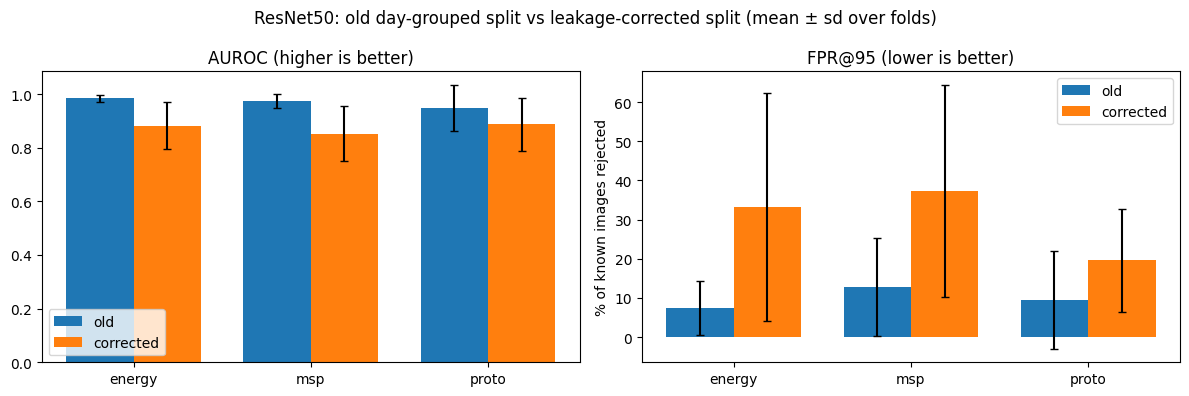

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, lab in [(axes[0], "AUROC", "AUROC (higher is better)"), (axes[1], "FPR95", "FPR@95 (lower is better)")]:
    t = res.groupby(["method", "protocol"])[metric].agg(["mean", "std"]).unstack("protocol")
    x = np.arange(len(t)); wbar = 0.38
    for i, p in enumerate([q for q in PROTOCOLS if q in t["mean"].columns]):
        scale = 100 if metric == "FPR95" else 1
        ax.bar(x + (i - 0.5) * wbar, t["mean"][p] * scale, wbar, yerr=t["std"][p] * scale, capsize=3, label=p)
    ax.set_xticks(x); ax.set_xticklabels(t.index); ax.set_title(lab); ax.legend()
    if metric == "FPR95": ax.set_ylabel("% of known images rejected")
plt.suptitle("ResNet50: old day-grouped split vs leakage-corrected split (mean ± sd over folds)")
plt.tight_layout(); plt.savefig(OUT / "old_vs_corrected.png", dpi=200); plt.show()

In [8]:
shutil.make_archive(str(OUT), "zip", OUT)
print("Download:", str(OUT) + ".zip")

Download: /kaggle/working/sentragrade_leakage.zip
